# Cybersecurity Incident Datasets – Incidents by Target Sector (Test Notebook)
This test notebook loads all four cybersecurity incident datasets in germany/data/raw/ using the project's centralized harmonization functions (harmonize_helpers.py and uild_and_verify_all.py) and visualizes the distribution of incidents by target sector:
1. **Maryland UMD Cyber Events** (Global vs. Germany)
2. **EuRepoC v1.3** (Global vs. Germany)
3. **KonBriefing Germany** (Germany only)
4. **Ransomware.live Germany** (Germany only)

In [1]:
# Import core data processing and visualization libraries
import pathlib
import sys
import warnings
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress non-critical warnings for clean notebook output
warnings.filterwarnings("ignore")

# Configure publication-grade visual theme
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

# Resolve paths relative to current working directory so notebook works from root or germany/notebooks
CWD = pathlib.Path.cwd()
if CWD.name == "notebooks":
    GERMANY_DIR = CWD.parent
elif (CWD / "germany").exists():
    GERMANY_DIR = CWD / "germany"
else:
    GERMANY_DIR = CWD

RAW_DIR = GERMANY_DIR / "data" / "raw"

# Import centralized harmonization helpers and dataset loaders
sys.path.insert(0, str(GERMANY_DIR / "scripts"))
from harmonize_helpers import fix_text_all, resolve_umd_sector, resolve_eurepoc_receiver_row_sector
from build_and_verify_all import load_eurepoc, load_konbriefing, load_ransomware_live


def plot_sector_barh(ax, sector_series, total_n, title, bar_color):
    """Plot a sorted horizontal bar chart of incident counts and shares per target sector."""
    counts = (
        sector_series.fillna("Unknown")
        .value_counts()
        .rename_axis("target_sector")
        .reset_index(name="incidents")
        .sort_values("incidents", ascending=True)
    )
    colors = ["#9e9e9e" if s == "Unknown" else bar_color for s in counts["target_sector"]]
    bars = ax.barh(counts["target_sector"], counts["incidents"], color=colors)
    max_val = counts["incidents"].max()
    ax.set_xlim(0, max_val * 1.24)
    for bar, val in zip(bars, counts["incidents"]):
        pct = val / total_n * 100
        ax.text(
            bar.get_width() + max_val * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{val:,} ({pct:.1f}%)",
            va="center",
            fontsize=9,
            fontweight="semibold",
        )
    ax.set_title(title)
    ax.set_xlabel("Number of Incidents")


print("Setup complete. Ready to load and plot all 4 incident datasets.")

Setup complete. Ready to load and plot all 4 incident datasets.


## 1. Maryland UMD Cyber Events (Global vs. Germany)
Maps UMD incidents via `resolve_umd_sector` from `harmonize_helpers.py`.

UMD Cyber Events — Global: 17,016 | Germany: 291


findfont: Failed to find font weight semibold for Arial, now using 700.


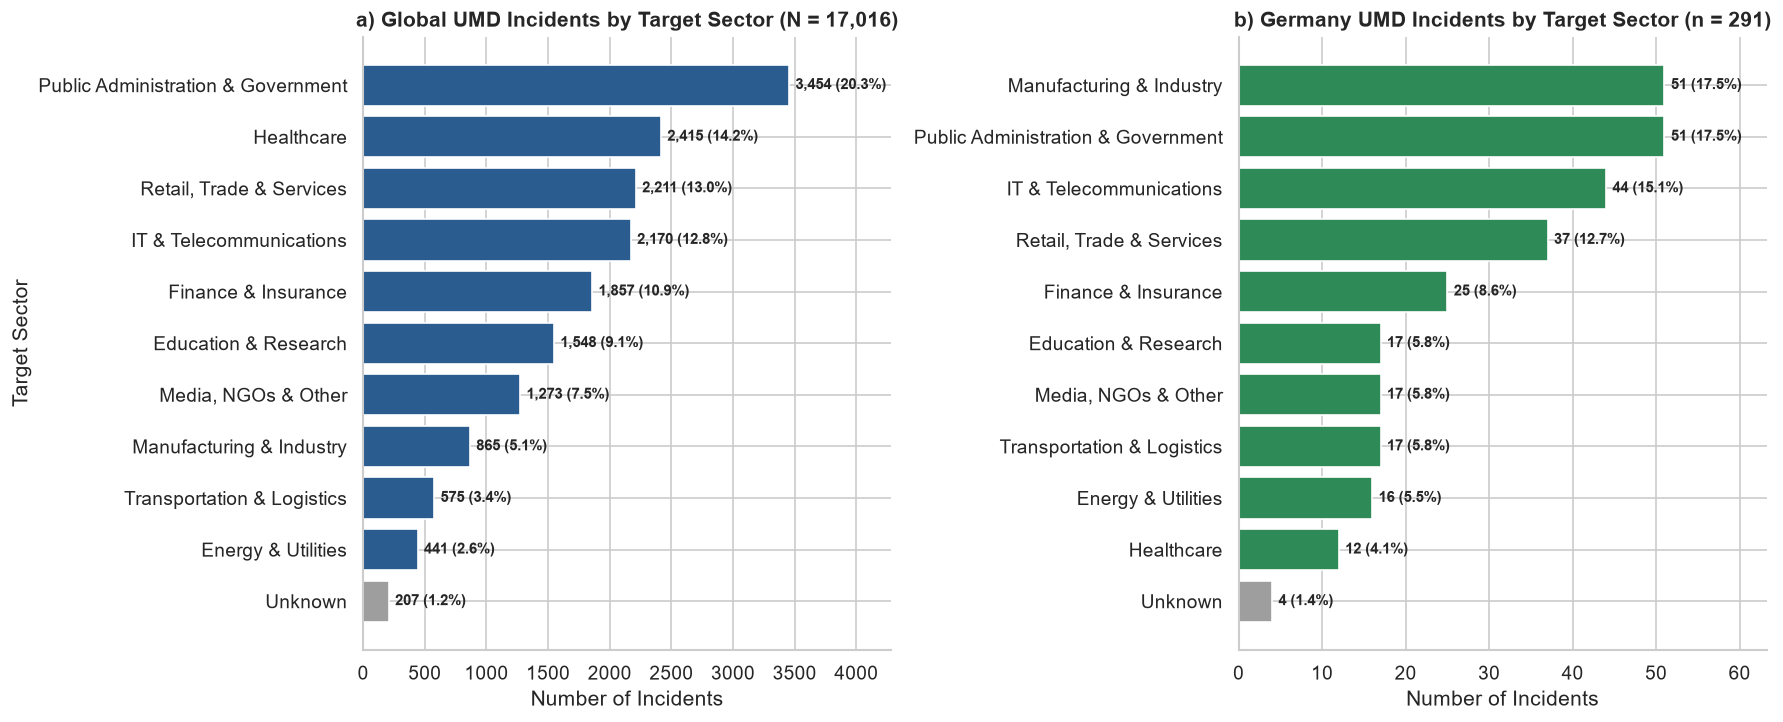

In [2]:
# Load raw UMD dataset and map target_sector using resolve_umd_sector
df_umd = pd.read_excel(RAW_DIR / "umd_cyber_events.xlsx")
df_umd["target_sector"] = [
    resolve_umd_sector(ind, org, desc)
    for ind, org, desc in zip(
        df_umd["industry"], df_umd["organization"], df_umd["description"]
    )
]
df_umd_de = df_umd[(df_umd["country"] == "Germany") | (df_umd["country_iso3"] == "DEU")].copy()

print(f"UMD Cyber Events — Global: {len(df_umd):,} | Germany: {len(df_umd_de):,}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2))
plot_sector_barh(
    ax1, df_umd["target_sector"], len(df_umd),
    f"a) Global UMD Incidents by Target Sector (N = {len(df_umd):,})", "#2b5c8f"
)
ax1.set_ylabel("Target Sector")
plot_sector_barh(
    ax2, df_umd_de["target_sector"], len(df_umd_de),
    f"b) Germany UMD Incidents by Target Sector (n = {len(df_umd_de):,})", "#2e8b57"
)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## 2. EuRepoC v1.3 (Global vs. Germany)
Resolves global EuRepoC incidents using `resolve_eurepoc_receiver_row_sector` (matching the receiver-aggregation logic in `load_eurepoc`) and German EuRepoC incidents via `load_eurepoc()` from `build_and_verify_all.py`.

Loading EuRepoC v1.3...


EuRepoC processed: 171 rows
EuRepoC v1.3 — Global: 3,414 | Germany: 171


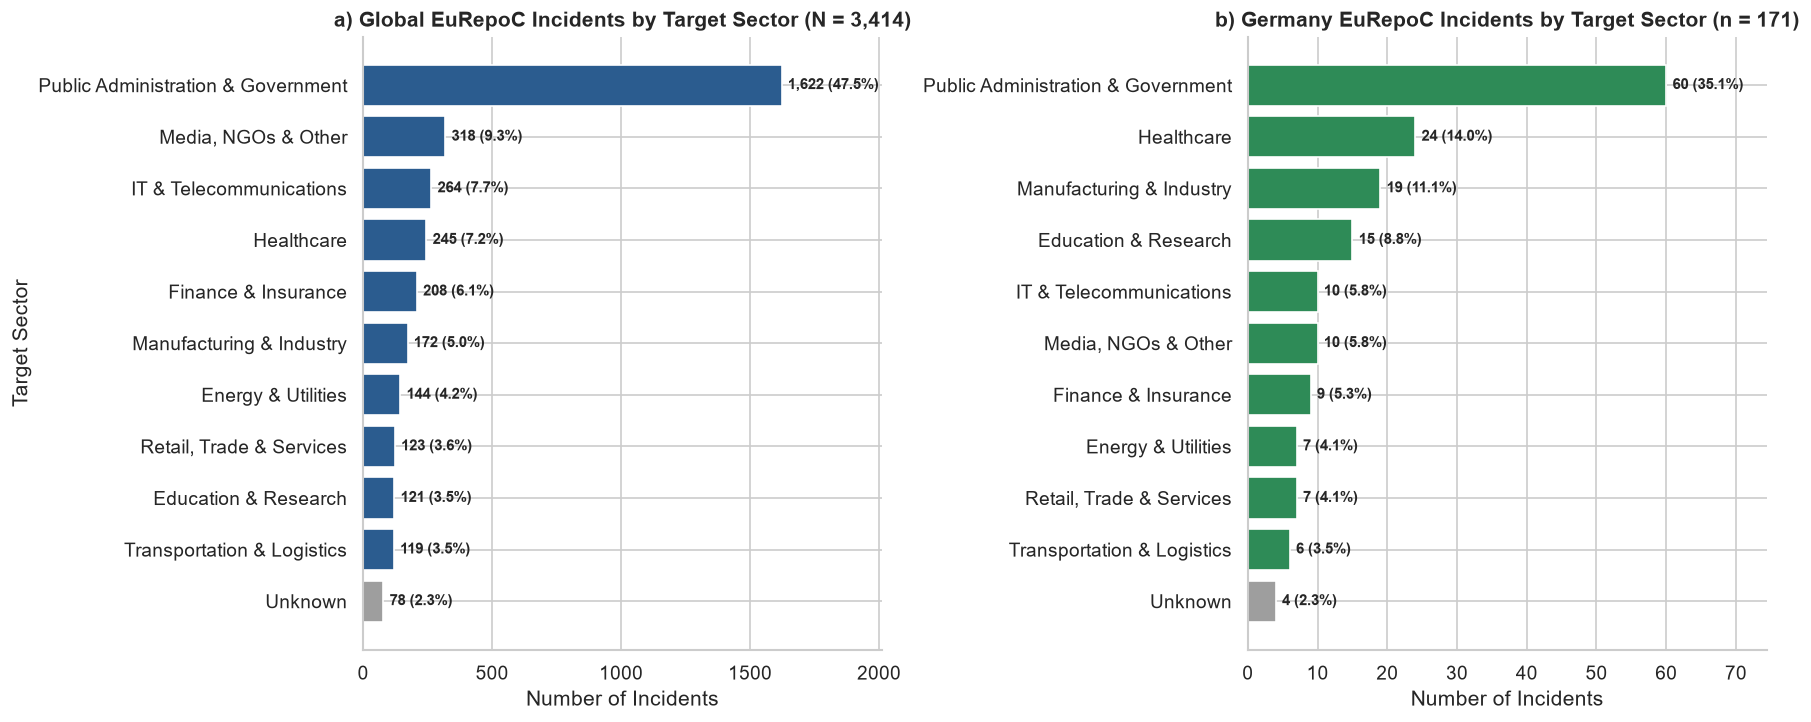

In [3]:
# Load global EuRepoC incident and receiver tables
eg = pd.read_csv(RAW_DIR / "eurepoc_global.csv", low_memory=False)
er = pd.read_csv(RAW_DIR / "eurepoc_receiver.csv", low_memory=False)

# Group receiver rows by incident_id for O(1) lookup per global incident
er_grouped = {iid: grp for iid, grp in er.groupby("incident_id")}
global_eur_sectors = []
for _, inc in eg.iterrows():
    iid = inc["incident_id"]
    sub_recs = er_grouped.get(iid)
    rec_sectors, named_sectors = [], []
    fallback_text = f"{inc['name']} {inc['description']}"
    if sub_recs is not None:
        for _, rr in sub_recs.iterrows():
            nm = fix_text_all(rr["name"])
            valid_nm = nm not in ("", "Not available", "Unknown", "nan")
            sec = resolve_eurepoc_receiver_row_sector(
                rr["category"], rr["subcategory"], nm if valid_nm else "", fallback_text
            )
            if sec != "Unknown":
                rec_sectors.append(sec)
                if valid_nm:
                    named_sectors.append(sec)
    if not rec_sectors:
        sec_primary = resolve_eurepoc_receiver_row_sector(
            str(inc.get("receiver_category", "")).split(";")[0],
            str(inc.get("receiver_subcategory", "")).split(";")[0],
            fix_text_all(inc.get("receiver_name", "")),
            fallback_text,
        )
    else:
        counts = Counter(rec_sectors)
        named_counts = Counter(named_sectors)
        sec_primary = sorted(counts.keys(), key=lambda s: (counts[s], named_counts[s]), reverse=True)[0]
    global_eur_sectors.append(sec_primary)

eg["target_sector"] = global_eur_sectors
df_eur_de = load_eurepoc()

print(f"EuRepoC v1.3 — Global: {len(eg):,} | Germany: {len(df_eur_de):,}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2))
plot_sector_barh(
    ax1, eg["target_sector"], len(eg),
    f"a) Global EuRepoC Incidents by Target Sector (N = {len(eg):,})", "#2b5c8f"
)
ax1.set_ylabel("Target Sector")
plot_sector_barh(
    ax2, df_eur_de["sector"], len(df_eur_de),
    f"b) Germany EuRepoC Incidents by Target Sector (n = {len(df_eur_de):,})", "#2e8b57"
)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## 3. KonBriefing Germany (Germany Only)
Loads and harmonizes `konbriefing_germany_enriched.csv` using `load_konbriefing()` from `build_and_verify_all.py`.

Loading KonBriefing Germany Enriched...


KonBriefing processed: 865 rows


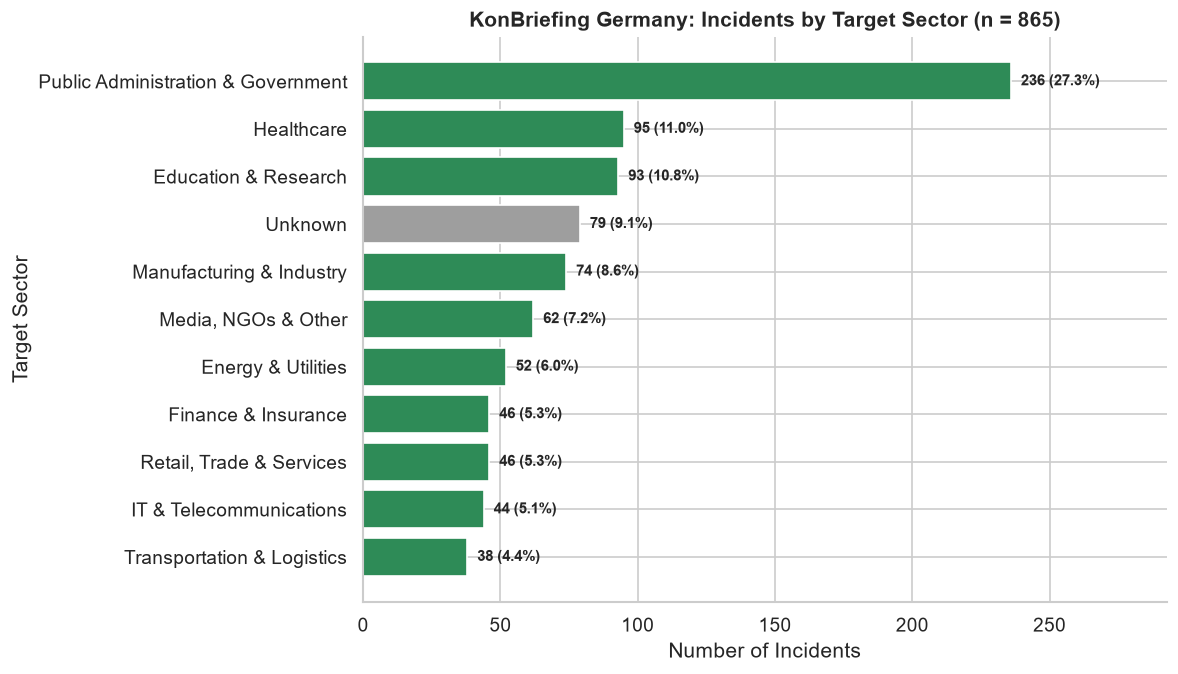

In [4]:
# Load Germany-only KonBriefing dataset via project loader
df_kb_de = load_konbriefing()

fig, ax = plt.subplots(figsize=(10, 5.8))
plot_sector_barh(
    ax, df_kb_de["sector"], len(df_kb_de),
    f"KonBriefing Germany: Incidents by Target Sector (n = {len(df_kb_de):,})", "#2e8b57"
)
ax.set_ylabel("Target Sector")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## 4. Ransomware.live Germany (Germany Only)
Loads and harmonizes `ransomware_live_germany.csv` using `load_ransomware_live()` from `build_and_verify_all.py`.

Loading Ransomware.live Germany...


Ransomware.live processed: 1170 rows


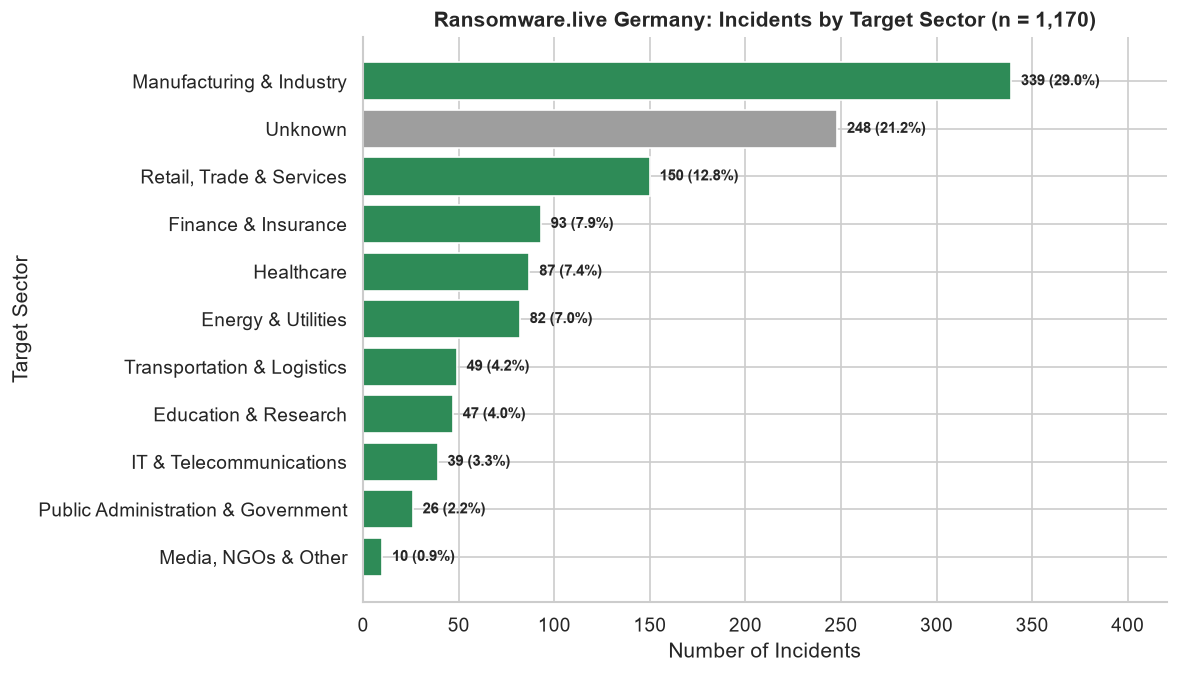

In [5]:
# Load Germany-only Ransomware.live dataset via project loader
df_rw_de = load_ransomware_live()

fig, ax = plt.subplots(figsize=(10, 5.8))
plot_sector_barh(
    ax, df_rw_de["sector"], len(df_rw_de),
    f"Ransomware.live Germany: Incidents by Target Sector (n = {len(df_rw_de):,})", "#2e8b57"
)
ax.set_ylabel("Target Sector")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()